# Product Classifier Training
### Smart Retail Checkout Project

- Backbone: **MobileNetV2**
- Head: just `GlobalAveragePooling2D → Dropout → Dense(output)`
- **Single training phase** — backbone stays frozen throughout, no fine-tuning stage
- **Max 10 epochs**, with early stopping so it can stop even sooner if validation loss plateaus

## 1. Setup & Imports

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.models import load_model

from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_recall_fscore_support
)



## 2. Configuration

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd().resolve()
print("Project directory:", PROJECT_DIR)

IMG_SIZE = (224, 224)
BATCH_SIZE = 8
NUM_CLASSES = 8
EPOCHS = 15

RANDOM_SEED = 42
tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)


Project directory: C:\Users\ravis\OneDrive\Desktop\Smart-Retail-Checkout-upgraded\AI-Powered-Smart-Retail-Checkout-main


## 3. Data Generators

MobileNetV2 expects inputs scaled to [-1, 1], handled by its own `preprocess_input` — not a manual `rescale=1./255`.

In [3]:
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=12,
    width_shift_range=0.08,
    height_shift_range=0.08,
    zoom_range=0.10,
    brightness_range=(0.85, 1.15),
    horizontal_flip=False
)

val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

# Explicit folder order: must match backend model output order.
folder_names = [
    "Amul_ice_cream", "cake", "cerave", "Hns_shampoo",
    "nestley_milk_powder", "plum", "thums_up", "wildstone"
]

class_names = [
    "Amul_Ice_Cream", "Cake", "CeraVe", "HnS_Shampoo",
    "Nestle_Milk_Powder", "Plum", "Thums_Up", "Wild_Stone"
]

training_set = train_datagen.flow_from_directory(
    str(PROJECT_DIR / 'Aug_Dataset' / 'Train'),
    classes=folder_names,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
    seed=RANDOM_SEED
)

validation_set = val_datagen.flow_from_directory(
    str(PROJECT_DIR / 'Aug_Dataset' / 'Val'),
    classes=folder_names,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

testing_set = test_datagen.flow_from_directory(
    str(PROJECT_DIR / 'Aug_Dataset' / 'Test'),
    classes=folder_names,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

assert list(training_set.class_indices.keys()) == folder_names, (
    "Training class order does not match the configured order."
)
assert list(validation_set.class_indices.keys()) == folder_names
assert list(testing_set.class_indices.keys()) == folder_names
assert len(class_names) == NUM_CLASSES

print("Backend-aligned class names:", class_names)
print("Training folder indexes:", training_set.class_indices)
print(f"Train: {training_set.samples} | Val: {validation_set.samples} | Test: {testing_set.samples}")

config_path = PROJECT_DIR / 'backend' / 'app' / 'config.py'
print("Backend config:", config_path)


Found 52 images belonging to 8 classes.


Found 9 images belonging to 8 classes.


Found 9 images belonging to 8 classes.


Backend-aligned class names: ['Amul_Ice_Cream', 'Cake', 'CeraVe', 'HnS_Shampoo', 'Nestle_Milk_Powder', 'Plum', 'Thums_Up', 'Wild_Stone']
Training folder indexes: {'Amul_ice_cream': 0, 'cake': 1, 'cerave': 2, 'Hns_shampoo': 3, 'nestley_milk_powder': 4, 'plum': 5, 'thums_up': 6, 'wildstone': 7}
Train: 52 | Val: 9 | Test: 9
Backend config: C:\Users\ravis\OneDrive\Desktop\Smart-Retail-Checkout-upgraded\AI-Powered-Smart-Retail-Checkout-main\backend\app\config.py


## 4. Build the Model

In [4]:
base_model = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model.trainable = False

print(f"Base model layers: {len(base_model.layers)}")
print(f"Base model output shape: {base_model.output_shape}")

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dropout(0.3),
    Dense(NUM_CLASSES, activation='softmax')
])

model.summary()


      0/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

  16384/9406464 ━━━━━━━━━━━━━━━━━━━━ 42s 5us/step

  49152/9406464 ━━━━━━━━━━━━━━━━━━━━ 26s 3us/step

  81920/9406464 ━━━━━━━━━━━━━━━━━━━━ 22s 2us/step

 139264/9406464 ━━━━━━━━━━━━━━━━━━━━ 22s 2us/step

...

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape           ┃      Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224          │ (None, 7, 7, 1280)     │    2,257,984 │
│ (Functional)                  │                        │              │
├───────────────────────────────┼────────────────────────┼──────────────┤
│ global_average_pooling2d      │ (None, 1280)           │            0 │
│ (GlobalAveragePooling2D)      │                        │              │
├───────────────────────────────┼────────────────────────┼──────────────┤
│ dropout (Dropout)             │ (None, 1280)           │            0 │
├───────────────────────────────┼────────────────────────┼──────────────┤
│ dense (Dense)                 │ (None, 8)              │       10,248 │
└───────────────────────────────┴────────────────────────┴──────────────┘

 Total params: 2,268,232 (8.65 MB)

 Trainable params: 10,248 (40.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 5. Train

In [5]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)

history = model.fit(
    training_set,
    validation_data=validation_set,
    epochs=EPOCHS,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/15


1/7 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.0000e+00 - loss: 2.5848

2/7 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.1667 - loss: 2.1151  

3/7 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.1500 - loss: 2.2708

4/7 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.1429 - loss: 2.4279

...

4/7 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 1.0000 - loss: 0.0253

5/7 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 1.0000 - loss: 0.0254

6/7 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 1.0000 - loss: 0.0255

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 1.0000 - loss: 0.0240

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - accuracy: 1.0000 - loss: 0.0240 - val_accuracy: 1.0000 - val_loss: 0.0251 - learning_rate: 0.0010


## 6. Training Curves

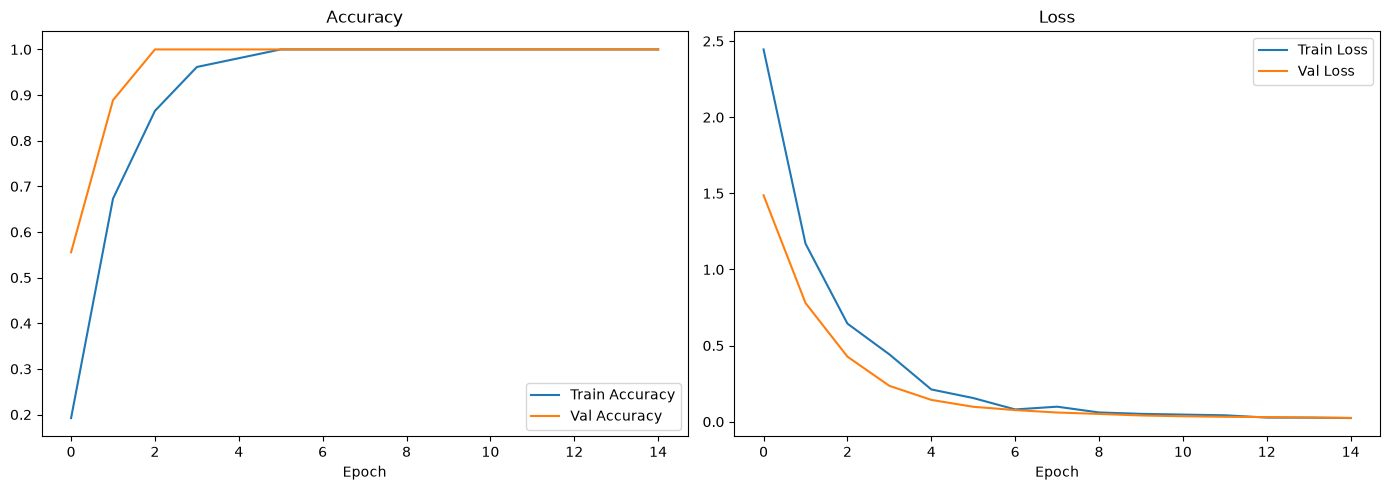

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'], label='Train Accuracy')
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy')
axes[0].set_title('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history.history['loss'], label='Train Loss')
axes[1].plot(history.history['val_loss'], label='Val Loss')
axes[1].set_title('Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.tight_layout()
plt.show()

## 7. Evaluate on the Test Set

In [7]:
test_loss, test_accuracy = model.evaluate(testing_set, verbose=1)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 1.0000 - loss: 0.0309

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 1.0000 - loss: 0.0293 



Test Loss: 0.0293
Test Accuracy: 1.0000


In [8]:
testing_set.reset()
y_pred_probs = model.predict(testing_set, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = testing_set.classes

overall_acc = accuracy_score(y_true, y_pred)
precision, recall, f1, support = precision_recall_fscore_support(y_true, y_pred, average='weighted')

print(f"Overall Accuracy:   {overall_acc:.4f}")
print(f"Weighted Precision: {precision:.4f}")
print(f"Weighted Recall:    {recall:.4f}")
print(f"Weighted F1-Score:  {f1:.4f}")

1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 604ms/step

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 523ms/step

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 528ms/step


Overall Accuracy:   1.0000
Weighted Precision: 1.0000
Weighted Recall:    1.0000
Weighted F1-Score:  1.0000


## 8. Sample Inference

In [9]:
def predict_single_image(image_path, model, class_names, confidence_threshold=0.75):
    image = Image.open(image_path).convert('RGB')
    test_image = image.resize((224, 224))
    test_image_arr = np.array(test_image).astype('float32')

    test_inp = np.expand_dims(test_image_arr, axis=0)
    test_inp = preprocess_input(test_inp)  # must match training-time preprocessing

    prediction = model.predict(test_inp, verbose=0)
    predicted_index = np.argmax(prediction)
    confidence = prediction[0][predicted_index]

    if confidence >= confidence_threshold:
        print(f"Accepted: {class_names[predicted_index]} ({confidence * 100:.2f}%)")
    else:
        print(f"Low Confidence: {class_names[predicted_index]} ({confidence * 100:.2f}%) - Please verify manually.")

    return class_names[predicted_index], confidence


predict_single_image('Sample_Images/CeraVe.jpg', model, class_names)

Low Confidence: CeraVe (52.37%) - Please verify manually.


('CeraVe', np.float32(0.5236975))

## 9. Save the Model

In [10]:
weights_path = PROJECT_DIR / 'custom_model.weights.h5'
model_path = PROJECT_DIR / 'full_model.keras'

model.save_weights(str(weights_path))
model.save(str(model_path))

print("Weights saved:", weights_path)
print("Model saved:", model_path)

loaded_model = load_model(str(model_path))
print("Reload check passed.")


Weights saved: C:\Users\ravis\OneDrive\Desktop\Smart-Retail-Checkout-upgraded\AI-Powered-Smart-Retail-Checkout-main\custom_model.weights.h5
Model saved: C:\Users\ravis\OneDrive\Desktop\Smart-Retail-Checkout-upgraded\AI-Powered-Smart-Retail-Checkout-main\full_model.keras


Reload check passed.
